In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ratings = pd.read_csv("../data/raw/ml-latest-small/ratings.csv")

In [2]:
ratings.head()
# shows the first 5 rows

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
ratings.shape
# how many rows and columnds does the table has

(100836, 4)

In [4]:
ratings.describe()
#shows count, mean, std, min, quartiles and max, not just the average

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [5]:
ratings.nunique()
# counts distinct values in each column

userId         610
movieId       9724
rating          10
timestamp    85043
dtype: int64

In [6]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [7]:
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
print(ratings["datetime"].min())
print(ratings["datetime"].max())
#Ratings span from March 1996 to September 2018, about 22 years

1996-03-29 18:36:55
2018-09-24 14:27:30


In [8]:
n_ratings = len(ratings)
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
density = n_ratings / (n_users * n_movies)
print(f"Density: {density:.4f}, Sparsity: {1 - density:.4f}")
#1 - (len(ratings)) / ((ratings["userId"].nunique()) * (ratings["movieId"].nunique()))
#show the sparsity
#98.3% of possible user–movie ratings are missing, so the model has to predict tastes from very little data.

Density: 0.0170, Sparsity: 0.9830


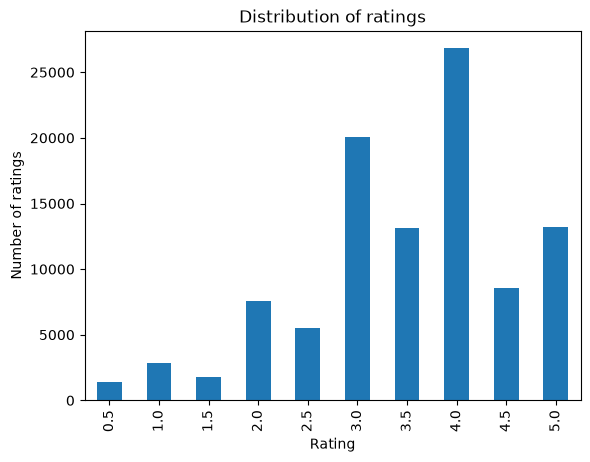

In [9]:
rating_counts = ratings["rating"].value_counts().sort_index()
rating_counts.plot(kind="bar")
plt.title("Distribution of ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
3446
0.16050815185052958


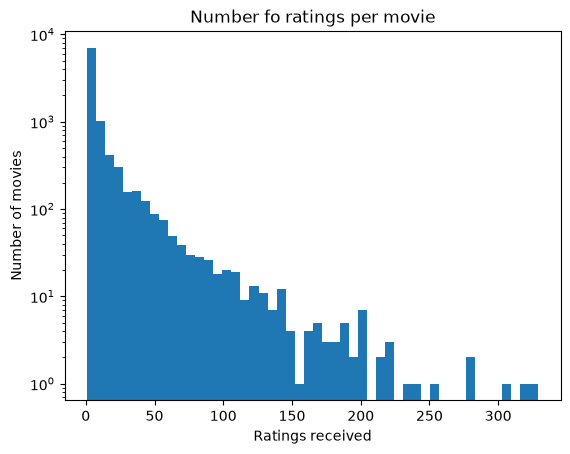

In [10]:
ratings_per_movie = ratings.groupby("movieId").size()
print(ratings_per_movie.describe())
print((ratings_per_movie == 1).sum())
print(ratings_per_movie.sort_values(ascending=False).head(100).sum() / len(ratings))
ratings_per_movie.plot(kind="hist", bins=50)
plt.title("Number fo ratings per movie")
plt.xlabel("Ratings received")
plt.ylabel("Number of movies")
plt.yscale("log")
plt.show()

#The distribution is heavily skewed: most movies have fewer than about 10 ratings, while a small number reach several hundred
#ratings_per_movie.sort_values(ascending=False).head()

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
14
userId
414    0.026756
599    0.024575
474    0.020905
448    0.018485
274    0.013348
         ...   
63     0.002688
325    0.002678
169    0.002668
332    0.002648
290    0.002648
Length: 100, dtype: float64


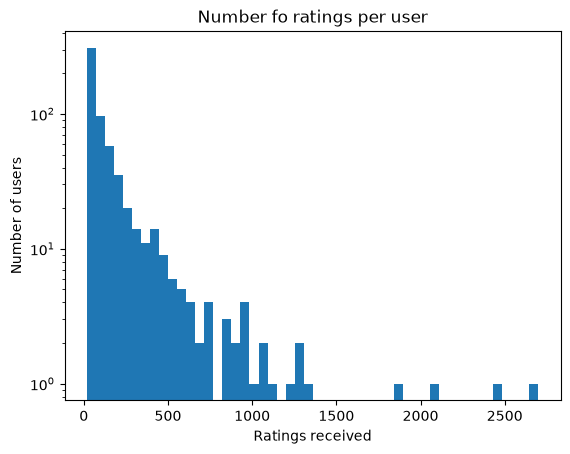

In [11]:
ratings_per_user = ratings.groupby("userId").size()
print(ratings_per_user.describe())
print((ratings_per_user == ratings_per_user.min()).sum())
print(ratings_per_user.sort_values(ascending=False).head(100) / len(ratings))
ratings_per_user.plot(kind="hist", bins=50)
plt.title("Number fo ratings per user")
plt.xlabel("Ratings received")
plt.ylabel("Number of users")
plt.yscale("log")
plt.show()
#Most users rated between 20 and about 150 movies, but a long tail of heavy users goes up to 2,698